<a href="https://colab.research.google.com/github/piihutanoch/pet-breed-classifier/blob/main/notebooks/05_app_dev.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
!pip install -q grad-cam gradio

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import json, sys, time, importlib
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

project_dir = Path("/content/drive/MyDrive/pet-breed-classifier")
artifacts_dir = project_dir / "artifacts"
data_dir = Path("/content/data")
data_dir.mkdir(parents=True, exist_ok=True)
sys.path.append(str(project_dir))

seed = 42
device = "cpu"

with open(artifacts_dir / "splits.json") as f:
    splits = json.load(f)
val_idx = splits["val"]

Mounted at /content/drive


In [5]:
!wget -q --show-progress https://s3.amazonaws.com/fast-ai-imageclas/oxford-iiit-pet.tgz -O /content/pets.tgz
!tar -xzf /content/pets.tgz -C /content/data

/content/pets.tgz   100%[===================>] 774.10M  38.8MB/s    in 19s     


### Setup
- `grad-cam` → heatmaps of where the model looked. `gradio` → web UI from Python functions.
- **CPU runtime on purpose**: the free Hugging Face Space has no GPU, so I test real-world speed.
- Dataset re-downloaded for threshold tuning on val and for picking example images.

In [6]:
%%writefile /content/drive/MyDrive/pet-breed-classifier/src/model.py

import torch.nn as nn
from torchvision import models


def build_model(name="efficientnet_b0", num_classes=37, freeze=True, pretrained=True):
    """
    Build an EfficientNet-B0 or ResNet50 model for breed classification.

    pretrained=True: Load ImageNet pretrained weights.
    pretrained=False: Initialise the backbone with random weights.
    freeze=True: Freeze backbone parameters while keeping the new classifier trainable.
    """

    if name == "efficientnet_b0":
        # Load EfficientNet-B0 with ImageNet weights if requested
        weights = models.EfficientNet_B0_Weights.DEFAULT if pretrained else None
        model = models.efficientnet_b0(weights=weights)

        # Freeze backbone parameters to prevent their updates during training
        if freeze:
            for param in model.parameters():
                param.requires_grad = False

        # Replace the original classification layer with a 37-class output layer
        in_features = model.classifier[1].in_features
        model.classifier[1] = nn.Linear(in_features, num_classes)

    elif name == "resnet50":
        # Load ResNet50 with ImageNet weights if requested
        weights = models.ResNet50_Weights.DEFAULT if pretrained else None
        model = models.resnet50(weights=weights)

        # Freeze backbone parameters
        if freeze:
            for param in model.parameters():
                param.requires_grad = False

        # Replace the original fully connected layer with a 37-class output layer
        in_features = model.fc.in_features
        model.fc = nn.Linear(in_features, num_classes)

    else:
        # Raise an error if an unsupported architecture is requested
        raise ValueError(f"Unknown model name: {name}")

    return model


# Identify the classifier layer name for each architecture
HEAD_PREFIX = {
    "efficientnet_b0": "classifier.",
    "resnet50": "fc."
}


def split_params(model, name):
    """
    Separate model parameters into backbone and classifier head groups.
    This allows different learning rates to be assigned to each group.
    """

    backbone, head = [], []

    # Iterate through all named model parameters
    for param_name, param in model.named_parameters():

        # Identify classifier head parameters using the architecture-specific prefix
        if param_name.startswith(HEAD_PREFIX[name]):
            head.append(param)
        else:
            backbone.append(param)

    return backbone, head


Overwriting /content/drive/MyDrive/pet-breed-classifier/src/model.py



### Model Architecture and Parameter Management

Created a reusable `build_model()` function supporting EfficientNet-B0 and ResNet50 for 37-class pet breed classification.

- **Pretrained Weights:** Supports loading ImageNet pretrained weights for transfer learning or initialising the model with random weights.
- **Freezing Layers:** Uses `requires_grad = False` to freeze backbone parameters when requested, allowing the newly added classifier head to be trained independently.
- **Classifier Replacement:** Replaces the original classification layer of each architecture with a linear layer containing 37 output units, corresponding to the pet breeds.
- **Architecture Validation:** Raises a `ValueError` if an unsupported model name is provided.

Also defined `HEAD_PREFIX` to identify the classifier layer in each architecture and implemented `split_params()` to separate backbone and classifier parameters into two groups. This allows different learning rates to be assigned to each group during training.


In [7]:
%%writefile /content/drive/MyDrive/pet-breed-classifier/src/predict.py

import json
from pathlib import Path

import torch

from src.data import get_eval_transform
from src.model import build_model


# Locate the artifacts directory relative to this file
DEFAULT_ARTIFACTS = Path(__file__).resolve().parent.parent / "artifacts"

# Initialise the evaluation transformations once for reuse
TRANSFORM = get_eval_transform()


def load_model(artifacts_dir=DEFAULT_ARTIFACTS, device="cpu"):
    """Load the trained model and return it with its class labels."""

    artifacts_dir = Path(artifacts_dir)

    # Load model configuration and index-to-breed mapping
    with open(artifacts_dir / "model_config.json") as f:
        config = json.load(f)

    with open(artifacts_dir / "classes.json") as f:
        idx_to_class = json.load(f)

    # Convert the index-to-class dictionary into an ordered list
    classes = [idx_to_class[str(i)] for i in range(config["num_classes"])]

    # Reconstruct the selected architecture without downloading pretrained weights
    model = build_model(
        config["name"],
        num_classes=config["num_classes"],
        freeze=False,
        pretrained=False
    )

    # Load the trained weights saved during model training
    model.load_state_dict(
        torch.load(artifacts_dir / "model.pt", map_location=device)
    )

    # Move model to the specified device and switch to evaluation mode
    model.to(device)
    model.eval()

    return model, classes, config["name"]


def predict(model, classes, image, k=5, device="cpu"):
    """Return the top-k predicted breeds and their probabilities."""

    # Ensure image has three colour channels
    image = image.convert("RGB")

    # Apply evaluation transformations and add batch dimension
    x = TRANSFORM(image).unsqueeze(0).to(device)

    # Perform inference without calculating gradients
    with torch.no_grad():
        probs = torch.softmax(model(x), dim=1)[0]

    # Extract the k highest-probability breed predictions
    top = probs.topk(k)

    # Return breed names paired with their probabilities
    return [
        (classes[i], float(p))
        for p, i in zip(top.values, top.indices)
    ]

Writing /content/drive/MyDrive/pet-breed-classifier/src/predict.py



### Model Loading and Prediction Pipeline

Created a prediction module to load the trained breed classifier and generate predictions for individual pet images.

- **Preprocessing:** Initialised the evaluation transformations once using `get_eval_transform()` to ensure consistent preprocessing during inference.
- **Model Loading:** Implemented `load_model()` to read the model configuration and class mappings, reconstruct the selected architecture and load its trained weights from `model.pt`.
- **Inference Mode:** Moved the model to the specified device and enabled evaluation mode using `model.eval()`.
- **Image Processing:** Implemented `predict()` to convert input images to RGB, apply evaluation transformations and add a batch dimension before passing them through the model.
- **Probability Calculation:** Used Softmax to convert raw model outputs into probabilities.
- **Top-k Predictions:** Extracted the k highest-probability breed predictions and returned them as breed-probability pairs.

The module separates model loading from prediction, allowing the trained model to be loaded once and reused for multiple image predictions without repeatedly reconstructing the architecture.


0.41s on CPU
True breed: Abyssinian
  Abyssinian                     72.8%
  Bengal                         17.0%
  Chihuahua                      0.7%
  Miniature Pinscher             0.7%
  Bombay                         0.4%


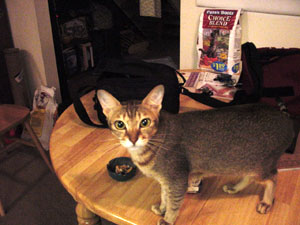

In [8]:
# Reload project modules to incorporate the latest code changes
import src.data, src.model, src.predict

importlib.reload(src.data)
importlib.reload(src.model)
importlib.reload(src.predict)

# Import prediction functions and image handling library
from src.predict import load_model, predict
from PIL import Image

# Load the trained model, breed labels and architecture name
model, classes, model_name = load_model(artifacts_dir, device="cpu")

# Load previously generated test predictions
pred_df = pd.read_csv(artifacts_dir / "predictions.csv")

# Select one test image for inference
sample = pred_df.iloc[0]

# Open the original test image
img = Image.open(
    data_dir / "oxford-iiit-pet" / "images" / sample["filename"]
)

# Measure the time taken to generate predictions
start = time.time()
result = predict(model, classes, img, k=5)

print(f"{time.time() - start:.2f}s on CPU")

# Display the actual breed and top-5 predicted breeds
print("True breed:", sample["true_breed"])

for breed, p in result:
    print(f"  {breed:<30} {p:.1%}")

# Display the test image
img



### Testing the Prediction Pipeline

Tested the newly implemented prediction module using a sample image from the test dataset.

- Reloaded the project modules to incorporate the latest changes and imported the `load_model()` and `predict()` functions.
- Loaded the trained model, breed class mappings and architecture name using `load_model()`.
- Read `predictions.csv` and selected the first test image along with its actual breed label.
- Passed the image to `predict()` to generate the five most likely breed predictions and their probabilities.
- Measured CPU inference time using `time.time()` to evaluate prediction speed.
- Displayed the actual breed, top-5 predictions with confidence percentages and the original image.

**Purpose:** To verify that the saved model can be successfully reconstructed and used for individual image predictions through the reusable prediction module.


In [9]:
%%writefile /content/drive/MyDrive/pet-breed-classifier/src/gradcam.py

import numpy as np
from torchvision import transforms
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

from src.data import get_eval_transform

# Preprocessing used by the trained model
TRANSFORM = get_eval_transform()

# Same resizing and cropping, but keeps the image suitable for display
DISPLAY = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224)
])


def get_target_layer(model, name):
    """Select the last convolutional block for Grad-CAM."""

    if name == "resnet50":
        return model.layer4[-1]

    if name == "efficientnet_b0":
        return model.features[-1]

    raise ValueError(f"Unknown model name: {name}")


def gradcam_overlay(model, name, image, class_idx, device="cpu"):
    """Generate a heatmap overlay for the selected class."""

    # Convert image to RGB
    image = image.convert("RGB")

    # Prepare image in the format expected by the model
    x = TRANSFORM(image).unsqueeze(0).to(device)

    # Generate Grad-CAM heatmap using the selected target layer
    with GradCAM(
        model=model,
        target_layers=[get_target_layer(model, name)]
    ) as cam:

        heatmap = cam(
            input_tensor=x,
            targets=[ClassifierOutputTarget(class_idx)]
        )[0]

    # Prepare original image as a normalized NumPy array
    rgb = np.array(DISPLAY(image), dtype=np.float32) / 255.0

    # Overlay heatmap on the original image
    return show_cam_on_image(rgb, heatmap, use_rgb=True)

Writing /content/drive/MyDrive/pet-breed-classifier/src/gradcam.py


###Grad-CAM Visualization
- Imports Grad-CAM utilities to generate visual explanations of model predictions.
- TRANSFORM preprocesses images using the same transformations as model evaluation.
- DISPLAY resizes and crops the original image for visualization.
- get_target_layer() selects the final convolutional layer of the chosen model.
- gradcam_overlay() generates a heatmap for a specified class and overlays it on the original image.
Purpose: Visualize which regions of an image influenced the model's prediction for a particular breed.

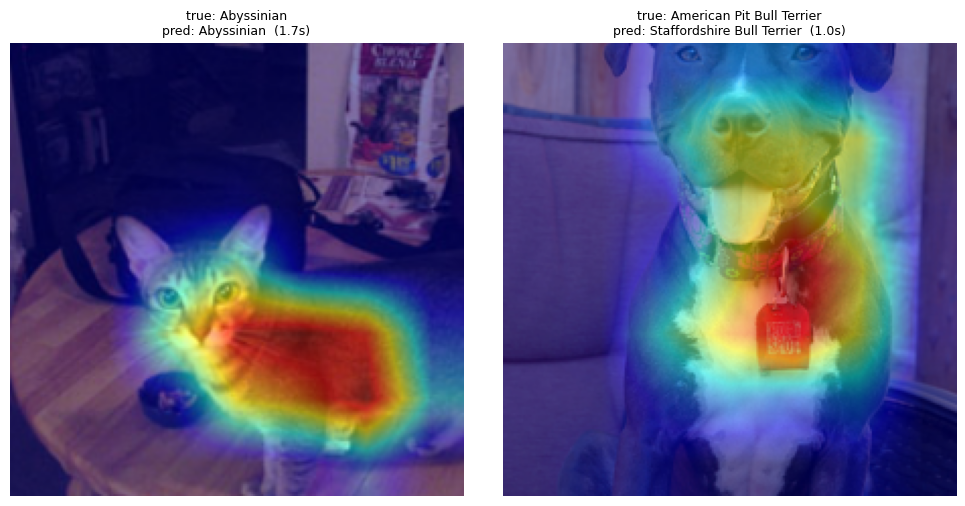

In [10]:
# Reload Grad-CAM module to use the latest changes
import src.gradcam
importlib.reload(src.gradcam)

from src.gradcam import gradcam_overlay

# Select one correctly classified image
right = pred_df[pred_df["correct"]].iloc[0]

# Select an image where an American Pit Bull Terrier was predicted as a Staffordshire Bull Terrier
wrong = pred_df[
    (pred_df["true_breed"] == "American Pit Bull Terrier") &
    (pred_df["pred_breed"] == "Staffordshire Bull Terrier")
].iloc[0]

# Create a figure with two side-by-side visualizations
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Generate Grad-CAM overlays for both images
for ax, row in zip(axes, [right, wrong]):

    # Load original image
    img = Image.open(
        data_dir / "oxford-iiit-pet" / "images" / row["filename"]
    )

    # Get the class index of the model's predicted breed
    pred_idx = classes.index(row["pred_breed"])

    # Measure Grad-CAM generation time
    start = time.time()
    overlay = gradcam_overlay(model, model_name, img, pred_idx)

    # Display heatmap overlay and prediction details
    ax.imshow(overlay)
    ax.set_title(
        f"true: {row['true_breed']}\n"
        f"pred: {row['pred_breed']}  ({time.time()-start:.1f}s)",
        fontsize=9
    )

    ax.axis("off")

# Adjust spacing and display both images
plt.tight_layout()
plt.show()

### Grad-CAM Visualization: Correct vs Incorrect Predictions

This cell compares the model's explanations for two predictions:

1. **Correct prediction:** Selects an image where the predicted breed matches the actual breed.
2. **Incorrect prediction:** Selects an image of an American Pit Bull Terrier that was misclassified as a Staffordshire Bull Terrier.

For each image, the cell:
- Loads the original image.
- Finds the class index of the predicted breed.
- Generates a Grad-CAM heatmap using `gradcam_overlay()`.
- Measures the time taken to generate the heatmap.
- Displays the heatmap over the original image, along with the true breed and predicted breed.

**Purpose:** Understand which regions of an image influence the model's predictions and compare its attention patterns when it classifies an image correctly versus incorrectly.

### Observations from Grad-CAM Visualizations

**1. Correct Prediction — Abyssinian**
- The model correctly identifies the cat as an Abyssinian.
- The strongest activation appears around the cat's body, particularly its torso.
- The model appears to use features from the animal's overall appearance to make its prediction.

**2. Incorrect Prediction — American Pit Bull Terrier**
- The actual breed is American Pit Bull Terrier, but the model predicts Staffordshire Bull Terrier.
- The heatmap highlights the dog's face, muzzle, and chest area.
- These two breeds have similar physical characteristics, which may contribute to the misclassification.

**Key Takeaway:** Grad-CAM helps visualize the image regions influencing a prediction. However, the highlighted regions do not necessarily represent the exact features used by the model, and the visualizations alone cannot establish why a misclassification occurred.

In [11]:
# Load the validation data loader
from src.data import get_loaders

_, val_loader = get_loaders(
    data_dir,
    splits["train"],
    val_idx,
    batch_size=32
)

# Store prediction confidence and correctness for each validation image
val_conf, val_correct = [], []

model.eval()

# Run inference without calculating gradients
with torch.no_grad():
    for images, labels in val_loader:

        # Get class probabilities and the highest-confidence prediction
        probs = torch.softmax(model(images), dim=1)
        conf, pred = probs.max(dim=1)

        # Collect confidence scores and whether each prediction is correct
        val_conf.extend(conf.tolist())
        val_correct.extend((pred == labels).tolist())

# Convert collected values into NumPy arrays
val_conf = np.array(val_conf)
val_correct = np.array(val_correct)

# Evaluate different confidence thresholds
rows = []

for t in np.arange(0.20, 0.85, 0.05):
    t = round(float(t), 2)

    rows.append({
        "threshold": t,

        # Percentage of correct predictions rejected below the threshold
        "correct_rejected_%": round(
            100 * (val_conf[val_correct] < t).mean(), 1
        ),

        # Percentage of incorrect predictions caught below the threshold
        "wrong_caught_%": round(
            100 * (val_conf[~val_correct] < t).mean(), 1
        ),
    })

# Display threshold comparison table
table = pd.DataFrame(rows)
print(table.to_string(index=False))

# Select the highest threshold that rejects at most 5% of correct predictions
ok = table[table["correct_rejected_%"] <= 5]
threshold = float(ok["threshold"].max())

print("\nChosen threshold:", threshold)

 threshold  correct_rejected_%  wrong_caught_%
      0.20                 0.2             3.7
      0.25                 0.2             3.7
      0.30                 0.4             7.4
      0.35                 0.8             7.4
      0.40                 1.5            18.5
      0.45                 2.1            22.2
      0.50                 2.7            33.3
      0.55                 3.6            33.3
      0.60                 5.0            44.4
      0.65                 7.4            44.4
      0.70                 9.9            55.6
      0.75                13.0            59.3
      0.80                18.9            66.7

Chosen threshold: 0.6


### Confidence Threshold Selection

This cell evaluates how different confidence thresholds affect the model's predictions using the validation dataset.

- Runs inference on validation images and records each prediction's confidence and correctness.
- Tests thresholds ranging from **0.20 to 0.80**, in increments of 0.05.
- **Correct rejected (%):** Percentage of correct predictions with confidence below the threshold.
- **Wrong caught (%):** Percentage of incorrect predictions with confidence below the threshold.
- Selects the highest threshold that rejects no more than **5% of correct predictions**.

**Purpose:** Find a confidence threshold that can flag potentially unreliable predictions while keeping the rejection of correct predictions low. Predictions below this threshold can be treated as uncertain.

In [14]:
# Load all supported images from the non-pet photos folder
nonpet_dir = project_dir / "nonpet_photos"

files = [
    p for p in nonpet_dir.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

rejected = 0

# Test the model on each non-pet image
for p in sorted(files):

    # Get the model's highest-confidence breed prediction
    best_breed, best_prob = predict(
        model, classes, Image.open(p), k=1
    )[0]

    # Reject images whose confidence is below the selected threshold
    is_rejected = best_prob < threshold
    rejected += is_rejected

    print(
        f"{'REJECTED' if is_rejected else 'accepted':<9} "
        f"{best_prob:5.1%}  {best_breed:<28} {p.name}"
    )

# Calculate the percentage of correctly classified test pets
# that would be rejected by this threshold
test_correct = pred_df[pred_df["correct"]]
pets_wrongly_rejected = (
    test_correct["confidence"] < threshold
).mean()

print(f"\nNon-pet photos rejected: {rejected}/{len(files)}")
print(
    f"Correct test pets wrongly rejected: "
    f"{pets_wrongly_rejected:.1%}"
)

# Load model configuration and save the selected threshold
with open(artifacts_dir / "model_config.json") as f:
    config = json.load(f)

config["threshold"] = threshold

with open(artifacts_dir / "model_config.json", "w") as f:
    json.dump(config, f, indent=2)

# Update evaluation metrics with rejection results
with open(artifacts_dir / "metrics.json") as f:
    metrics = json.load(f)

metrics["threshold"] = threshold
metrics["nonpet_rejected"] = int(rejected)
metrics["nonpet_total"] = len(files)
metrics["pets_wrongly_rejected"] = round(
    float(pets_wrongly_rejected), 4
)

with open(artifacts_dir / "metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

REJECTED   9.6%  Yorkshire Terrier            @ELLE.jpg
REJECTED   8.0%  Havanese                     Breathtaking Swiss Alps Village Inspo_ Swiss Travel & Alpine Scenery Aesthetic.jpg
REJECTED  10.8%  Havanese                     Cozy Dream Cottage Home Inspiration _ Romantic House Aesthetic.jpg
REJECTED  11.3%  Havanese                     Lily.jpg
REJECTED  11.5%  Basset Hound                 Shannon Lynch.jpg
REJECTED   9.2%  Newfoundland                 animal.jpg
REJECTED   9.1%  Ragdoll                      dkr.jpg
REJECTED   8.8%  Shiba Inu                    download.jpg
REJECTED   8.2%  German Shorthaired           frits.jpg
REJECTED   6.3%  American Pit Bull Terrier    ggg.jpg
REJECTED  14.5%  Sphynx                       haha love themmmmn.jpg
REJECTED   6.5%  Shiba Inu                    idk.jpg
REJECTED  14.2%  Beagle                       idkagain.jpg
REJECTED  10.5%  Ragdoll                      lp.jpg
REJECTED  14.1%  Yorkshire Terrier            madhumalati dake ay.jp

### Non-Pet Image Rejection and Threshold Evaluation

This cell tests the selected confidence threshold on images that do not contain pets.

- Loads images from the `nonpet_photos` folder.
- Uses the trained model to predict the most likely breed for each image.
- Rejects predictions whose confidence is below the selected threshold and accepts the rest.
- Calculates how many non-pet images are rejected.
- Checks how many correctly classified test pet images would also be wrongly rejected.
- Saves the selected threshold and rejection statistics in `model_config.json` and `metrics.json`.

### Non-Pet Image Rejection Results

The selected confidence threshold was tested on non-pet images to evaluate the model's ability to reject uncertain predictions.

**Results:**
- **Non-pet images rejected:** 27 out of 27 (100%).
- **Correct test pet images wrongly rejected:** 6.2%.

All 27 non-pet images received confidence scores below the selected threshold and were rejected. However, 6.2% of correctly classified pet images were also rejected.

**Conclusion:** The confidence threshold successfully rejected all non-pet images in this test while retaining 93.8% of correctly classified test pet images. This demonstrates a useful confidence-based rejection mechanism, although it does not guarantee that all unseen non-pet images will be rejected.

In [15]:
# Create a folder to store example pet images
examples_dir = artifacts_dir / "examples"
examples_dir.mkdir(exist_ok=True)

# Select correctly classified images, keeping only one image per breed
good = pred_df[pred_df["correct"]].drop_duplicates("true_breed")

# Randomly select 3 cat images and 3 dog images
# random_state ensures the same images are selected each time
picks = pd.concat([
    good[good["species"] == "cat"].sample(3, random_state=seed),
    good[good["species"] == "dog"].sample(3, random_state=seed)
])

# Save the selected images in the examples folder
for _, row in picks.iterrows():

    # Load the original image and convert it to RGB
    img = Image.open(
        data_dir / "oxford-iiit-pet" / "images" / row["filename"]
    ).convert("RGB")

    # Resize the image while preserving its aspect ratio
    img.thumbnail((500, 500))

    # Save the image with reduced file size
    img.save(examples_dir / row["filename"], quality=85)

    print("saved", row["filename"], "→", row["true_breed"])

saved Siamese_209.jpg → Siamese
saved Russian_Blue_201.jpg → Russian Blue
saved Abyssinian_201.jpg → Abyssinian
saved german_shorthaired_191.jpg → German Shorthaired
saved pomeranian_191.jpg → Pomeranian
saved american_bulldog_203.jpg → American Bulldog


### Selecting Example Pet Images

This cell creates a collection of example images for the project.

- Creates an `examples` folder inside the artifacts directory.
- Selects correctly classified images, keeping one image per breed.
- Randomly picks **3 cat images and 3 dog images** using a fixed random seed for reproducibility.
- Resizes the selected images to fit within 500 × 500 pixels while maintaining their aspect ratios.
- Saves the images in the examples folder and prints their filenames and breed labels.

Prepare a small collection of correctly classified cat and dog images for use in the project's dashboard and README.

In [17]:
%%writefile /content/drive/MyDrive/pet-breed-classifier/app.py

import json
from pathlib import Path

import matplotlib
matplotlib.use("Agg")  # Render plots without requiring a display

import matplotlib.pyplot as plt
import pandas as pd
import gradio as gr

from src.predict import load_model, predict
from src.gradcam import gradcam_overlay

ROOT = Path(__file__).resolve().parent
ART = ROOT / "artifacts"


# ---------- Load project resources once at startup ----------

model, classes, model_name = load_model(ART)

with open(ART / "model_config.json") as f:
    THRESHOLD = json.load(f)["threshold"]

with open(ART / "metrics.json") as f:
    metrics = json.load(f)

per_class = pd.read_csv(ART / "per_class.csv")
pairs = pd.read_csv(ART / "confused_pairs.csv")

example_files = sorted(
    str(p) for p in (ART / "examples").glob("*.jpg")
)


# ---------- Tab 1: Predict ----------

def classify(image):

    # Handle cases where no image has been uploaded
    if image is None:
        return {}, None, "Upload a photo of a cat or dog."

    # Generate the top-5 breed predictions
    top5 = predict(model, classes, image, k=5)
    best_breed, best_prob = top5[0]

    # Generate a Grad-CAM visualization for the top prediction
    heatmap = gradcam_overlay(
        model,
        model_name,
        image,
        classes.index(best_breed)
    )

    # Check whether the highest confidence score meets the threshold
    if best_prob < THRESHOLD:
        message = (
            f"⚠️ **Not confident** (top score {best_prob:.0%}). "
            "Is this a clear photo of a cat or dog?"
        )
    else:
        message = f"### {best_breed}\n{best_prob:.0%} confidence"

    # Convert predictions into the dictionary format expected by gr.Label
    label_dict = {
        breed: prob for breed, prob in top5
    }

    return label_dict, heatmap, message


# ---------- Tab 2: Model performance ----------

def per_class_plot(choice):

    # Filter results according to the selected species
    if choice == "Cats":
        df = per_class[per_class["species"] == "cat"]
    elif choice == "Dogs":
        df = per_class[per_class["species"] == "dog"]
    else:
        df = per_class

    # Sort breeds by accuracy
    df = df.sort_values("accuracy")

    # Create a horizontal bar chart
    fig, ax = plt.subplots(
        figsize=(8, 0.28 * len(df) + 1)
    )

    ax.barh(df["breed"], df["accuracy"] * 100)
    ax.set_xlabel("Test accuracy (%)")
    ax.set_xlim(0, 100)
    ax.set_title(f"Per-breed accuracy: {choice}")

    fig.tight_layout()
    return fig


# Prepare a Markdown summary of the model's evaluation metrics
metrics_md = f"""
| Metric | Value |
|---|---|
| Test accuracy | **{metrics['test_acc']:.1%}** |
| Top-5 accuracy | {metrics['top5_acc']:.1%} |
| Macro F1 | {metrics['macro_f1']:.3f} |
| Cats / Dogs accuracy | {metrics['cat_acc']:.1%} / {metrics['dog_acc']:.1%} |
| Test images | {metrics['n_test']:,} |

**Baseline vs fine-tuned (test accuracy):**
Frozen EfficientNet-B0 **{metrics['baseline_test_acc']:.1%}**
→ fine-tuned {metrics['model']} **{metrics['test_acc']:.1%}**

**Confidence threshold:** {metrics['threshold']:.2f}

Rejected {metrics['nonpet_rejected']}/{metrics['nonpet_total']}
non-pet photos and wrongly rejected
{metrics['pets_wrongly_rejected']:.1%} of correctly classified pets.
"""


# ---------- Tab 3: Error explorer ----------

# Create a lookup dictionary for confused breed pairs
pair_lookup = {}

for _, row in pairs.iterrows():

    label = (
        f"{row['true']} → {row['predicted']} "
        f"({row['count']} images)"
    )

    pair_lookup[label] = row


def show_pair(choice):

    # Retrieve information about the selected breed pair
    row = pair_lookup[choice]

    # Construct the filename prefix used for saved error images
    prefix = (
        f"{row['true']}__{row['predicted']}__"
    ).replace(" ", "_")

    # Find example images for the selected confusion pair
    images = sorted(
        str(p) for p in (ART / "errors").glob(prefix + "*.jpg")
    )

    # Prepare a short explanation
    text = (
        f"**{row['count']}** test images of **{row['true']}** "
        f"were predicted as **{row['predicted']}**. Examples:"
    )

    return text, images


# ---------- Gradio interface layout ----------

with gr.Blocks(title="Pet Breed Classifier") as demo:

    gr.Markdown(
        "# 🐾 Pet Breed Classifier\n"
        "37 cat and dog breeds · "
        f"fine-tuned {metrics['model']} · "
        f"test accuracy {metrics['test_acc']:.1%}"
    )

    # Tab 1: Upload an image and predict its breed
    with gr.Tab("Predict"):

        with gr.Row():

            with gr.Column():
                image_in = gr.Image(
                    type="pil",
                    sources=["upload", "webcam"],
                    label="Photo"
                )

                predict_btn = gr.Button(
                    "Predict",
                    variant="primary"
                )

                gr.Examples(
                    examples=[[f] for f in example_files],
                    inputs=[image_in]
                )

            with gr.Column():
                message_out = gr.Markdown()

                label_out = gr.Label(
                    num_top_classes=5,
                    label="Top 5 breeds"
                )

                cam_out = gr.Image(
                    label="Grad-CAM: where the model looked"
                )

        # Connect the Predict button to the classification function
        predict_btn.click(
            classify,
            inputs=image_in,
            outputs=[label_out, cam_out, message_out]
        )

    # Tab 2: Display model evaluation results
    with gr.Tab("Model performance"):

        gr.Markdown(metrics_md)

        # Allow users to filter breed accuracy by species
        species_radio = gr.Radio(
            ["All", "Cats", "Dogs"],
            value="All",
            label="Show"
        )

        bar_plot = gr.Plot(
            value=per_class_plot("All")
        )

        # Update the chart when the selected species changes
        species_radio.change(
            per_class_plot,
            inputs=species_radio,
            outputs=bar_plot
        )

        # Display the normalized confusion matrix
        gr.Image(
            value=str(ART / "confusion.png"),
            label="Confusion matrix (row-normalized)",
            interactive=False
        )

    # Tab 3: Explore commonly confused breed pairs
    with gr.Tab("Error explorer"):

        first_pair = list(pair_lookup)[0]

        pair_dd = gr.Dropdown(
            choices=list(pair_lookup),
            value=first_pair,
            label="Most-confused pairs"
        )

        pair_text = gr.Markdown()

        pair_gallery = gr.Gallery(
            columns=4,
            height="auto",
            label="Misclassified test images"
        )

        # Update the gallery when a different breed pair is selected
        pair_dd.change(
            show_pair,
            inputs=pair_dd,
            outputs=[pair_text, pair_gallery]
        )

        # Display examples when the page first loads
        demo.load(
            show_pair,
            inputs=pair_dd,
            outputs=[pair_text, pair_gallery]
        )


# Launch the Gradio application
if __name__ == "__main__":
    demo.launch()

Overwriting /content/drive/MyDrive/pet-breed-classifier/app.py


## Building the Gradio Application

This cell creates the interactive web application for the Pet Breed Classifier using **Gradio**.

The application is organised into three tabs:

### 1. Predict
- Accepts images through file uploads or a webcam.
- Uses the trained model to predict the top 5 breeds.
- Applies the confidence threshold to flag uncertain predictions.
- Generates a Grad-CAM visualization to highlight image regions influencing the prediction.
- Provides example images for testing.

### 2. Model Performance
- Displays evaluation metrics such as test accuracy, top-5 accuracy and macro F1.
- Compares the frozen baseline model with the fine-tuned model.
- Shows per-breed accuracy through an interactive bar chart.
- Displays the normalized confusion matrix.

### 3. Error Explorer
- Allows users to select commonly confused breed pairs.
- Displays the number of test images involved in each confusion pair.
- Shows example images that were misclassified.

The model, configuration, metrics and supporting files are loaded once when the application starts.

**Purpose:** Integrate the trained model, prediction pipeline, Grad-CAM visualizations and evaluation results into one interactive application.

In [18]:
# Reload project modules to include the latest changes
import src.predict
import src.gradcam

importlib.reload(src.model)
importlib.reload(src.predict)
importlib.reload(src.gradcam)

# Import Gradio and close any previously running applications
import gradio as gr
gr.close_all()

# Import and reload the latest application code
import app
importlib.reload(app)

# Launch the Gradio application
app.demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://850b2f2f16889c1e26.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Launching the Gradio Application

This cell reloads the updated project modules and launches the Gradio web application.

- Reloads the model, prediction and Grad-CAM modules to incorporate the latest changes.
- Closes any previously running Gradio applications to avoid conflicts.
- Imports and reloads `app.py` to ensure the latest interface code is used.
- Launches the application using `app.demo.launch()`.

**Purpose:** Start the interactive Pet Breed Classifier application and test its prediction, model performance and error exploration features.